<a href="https://colab.research.google.com/github/FaishalFaruq02/DataAnalyst-Pembelian-Mobil/blob/main/Python_Data_Analysis_Showroom_Mobil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📝 Tugas: Python & Data Analysis
### Studi Kasus: Data Penjualan Showroom Mobil (10 Cabang)

Kerjakan 5 soal di bawah ini. Semua soal pakai dataset yang sama seperti di kelas.

🔗 [Data Penjualan Showroom Mobil 10 Cabang](https://docs.google.com/spreadsheets/d/1GuFkH44urw4ACqt5gsWhi1Scei0pGS2L/edit?usp=drive_link&ouid=106485154383908444810&rtpof=true&sd=true)

**Petunjuk pengerjaan:**

- Isi kode kamu di cell kode yang sudah disediakan di bawah tiap soal, tepat di bawah komentar instruksi.
- Boleh nambah cell baru sendiri kalau butuh cek data dulu sebelum jawab.
- Boleh pakai fitur AI di Colab kalau stuck, tapi coba dulu sendiri ya, biar makin paham.
- Jangan lupa jalankan cell paling atas dulu (import + load data) sebelum ngerjain soal-soal di bawahnya.

**Daftar soal:**

| No | Soal | Tingkat Kesulitan |
|---|---|---|
| 1 | Ukuran & isi awal data | Gampang |
| 2 | Jumlah transaksi per kategori mobil | Gampang |
| 3 | Cabang dengan transaksi terbanyak | Gampang |
| 4 | Bersihkan dan siapkan data (cleansing + formatting) | Sedang |
| 5 | Kombinasi cabang & kategori dengan pendapatan tertinggi | Agak Sulit |

---

## Setup (jalankan dulu sebelum mulai ngerjain)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url_data = "https://docs.google.com/spreadsheets/d/1GuFkH44urw4ACqt5gsWhi1Scei0pGS2L/export?format=csv"
df = pd.read_csv(url_data)

print("Data berhasil di-load!")
print("Jumlah baris dan kolom:", df.shape)
df.head()


Data berhasil di-load!
Jumlah baris dan kolom: (10000, 16)


,sales_date,order_id,customer_name,branch,product_name,category,color,price,quantity,payment_type,trade_in,discount,total,total_sales,status,branch_address
0,2025-12-13,TRX00001,Customer_913,Jakarta,Daihatsu Xenia 1.5 R CVT,MPV,Silver Metalik,240000000,1,Cash + Trade In,74000000,0,240000000,166000000,completed,"Jl. MT. Haryono No. 12, Jakarta"
1,2025-10-15,TRX00002,Customer_261,Jakarta,Toyota Rush 1.5 S GR Sport CVT,SUV,Hitam Metalik,300000000,1,Kredit,0,0,300000000,300000000,completed,"Jl. MT. Haryono No. 12, Jakarta"
2,2025-01-04,TRX00003,Customer_4465,Kendari,Honda BR-V 1.5 E CVT,MPV,Merah,310000000,1,Kredit + Trade In,111000000,0,310000000,199000000,completed,"Jl. Ahmad Yani No. 33, Kendari"
3,2025-02-17,TRX00004,Customer_2788,Padang,Honda Brio Satya E CVT,Hatchback,Merah,190000000,1,Kredit,0,0,190000000,190000000,completed,"Jl. Khatib Sulaiman No. 10, Padang"
4,2025-10-02,TRX00005,Customer_2941,Karawang,Isuzu D-Max Double Cabin 4x4 AT,Pickup,Hitam Metalik,520000000,1,Cash + Trade In,93000000,0,520000000,427000000,refund,"Jl. Ahmad Yani No. 5, Karawang"


> ⚠️ Kalau load data-nya error, cek lagi akses sharing sheet-nya (harus "Anyone with the link" minimal Viewer), atau upload manual filenya ke Colab.


---
## Soal 1 :

Tampilkan:

1. Jumlah baris dan jumlah kolom dari data (`df`)
2. Nama-nama semua kolom yang ada
3. 10 baris pertama dari data


In [ ]:
# 1. Tampilkan jumlah baris dan jumlah kolom dari df
print(f"Jumlah baris: {df.shape[0]}, Jumlah kolom: {df.shape[1]}")

# 2. Tampilkan nama-nama semua kolom
print("Nama-nama kolom:", df.columns.tolist())

# 3. Tampilkan 10 baris pertama dari data
df.head(10)

Jumlah baris: 10000, Jumlah kolom: 16
Nama-nama kolom: ['sales_date', 'order_id', 'customer_name', 'branch', 'product_name', 'category', 'color', 'price', 'quantity', 'payment_type', 'trade_in', 'discount', 'total', 'total_sales', 'status', 'branch_address']


,sales_date,order_id,customer_name,branch,product_name,category,color,price,quantity,payment_type,trade_in,discount,total,total_sales,status,branch_address
0,2025-12-13,TRX00001,Customer_913,Jakarta,Daihatsu Xenia 1.5 R CVT,MPV,Silver Metalik,240000000,1,Cash + Trade In,74000000,0,240000000,166000000,completed,"Jl. MT. Haryono No. 12, Jakarta"
1,2025-10-15,TRX00002,Customer_261,Jakarta,Toyota Rush 1.5 S GR Sport CVT,SUV,Hitam Metalik,300000000,1,Kredit,0,0,300000000,300000000,completed,"Jl. MT. Haryono No. 12, Jakarta"
2,2025-01-04,TRX00003,Customer_4465,Kendari,Honda BR-V 1.5 E CVT,MPV,Merah,310000000,1,Kredit + Trade In,111000000,0,310000000,199000000,completed,"Jl. Ahmad Yani No. 33, Kendari"
3,2025-02-17,TRX00004,Customer_2788,Padang,Honda Brio Satya E CVT,Hatchback,Merah,190000000,1,Kredit,0,0,190000000,190000000,completed,"Jl. Khatib Sulaiman No. 10, Padang"
4,2025-10-02,TRX00005,Customer_2941,Karawang,Isuzu D-Max Double Cabin 4x4 AT,Pickup,Hitam Metalik,520000000,1,Cash + Trade In,93000000,0,520000000,427000000,refund,"Jl. Ahmad Yani No. 5, Karawang"
5,2025-07-05,TRX00006,Customer_3101,Bandung,Wuling Air ev Long Range,City Car (EV),Abu-abu,250000000,1,Kredit,0,0,250000000,250000000,completed,"Jl. Soekarno Hatta No. 88, Bandung"
6,2025-02-21,TRX00007,Customer_570,Jakarta,Honda BR-V 1.5 E CVT,MPV,Hitam Metalik,310000000,2,Kredit + Trade In,224000000,0,620000000,396000000,completed,"Jl. MT. Haryono No. 12, Jakarta"
7,2025-12-16,TRX00008,Customer_2989,Pontianak,Mitsubishi Pajero Sport Dakar 4x2 AT,SUV,Putih Pearl,580000000,1,Kredit,0,0,580000000,580000000,completed,"Jl. Ahmad Yani No. 45, Pontianak"
8,2025-11-24,TRX00009,Customer_1402,Semarang,Honda BR-V 1.5 E CVT,MPV,Silver Metalik,310000000,1,Kredit,0,0,310000000,310000000,completed,"Jl. Setiabudi No. 60, Semarang"
9,2025-07-25,TRX00010,Customer_1800,Karawang,Toyota Innova Zenix 2.0 V CVT,MPV,Hitam Metalik,450000000,1,Kredit + Trade In,167000000,0,450000000,283000000,completed,"Jl. Ahmad Yani No. 5, Karawang"


---
## Soal 2: Jumlah Transaksi per Kategori Mobil

Hitung ada berapa banyak transaksi untuk masing-masing kategori mobil (kolom `category`), diurutkan dari yang paling banyak.

**Bonus (opsional):** buat bar chart dari hasilnya.


Jumlah Transaksi per Kategori Mobil:
category
SUV              4565
MPV              3915
Hatchback         519
Pickup            516
City Car (EV)     485
Name: count, dtype: int64


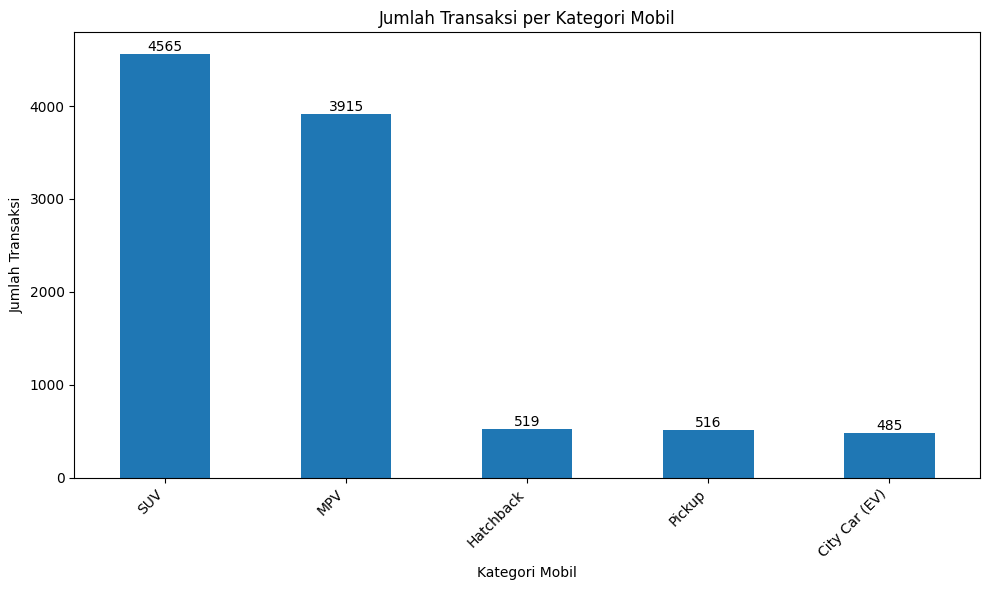

In [ ]:
# Hitung jumlah transaksi per kategori mobil (category), urutkan dari yang paling banyak
kategori_transaksi = df['category'].value_counts()
print("Jumlah Transaksi per Kategori Mobil:")
print(kategori_transaksi)

# (opsional) buat bar chart dari hasilnya
plt.figure(figsize=(10, 6))
hasil = kategori_transaksi.plot(kind='bar')
plt.title('Jumlah Transaksi per Kategori Mobil')
plt.xlabel('Kategori Mobil')
plt.ylabel('Jumlah Transaksi')
plt.xticks(rotation=45, ha='right')
for p in hasil.patches:
    hasil.annotate(str(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', rotation=0)

plt.tight_layout()
plt.show()

---
## Soal 3: Cabang dengan Transaksi Terbanyak

Dari semua cabang yang ada, cabang mana yang punya **jumlah transaksi terbanyak** (bukan pendapatan, tapi jumlah baris transaksinya)? Tampilkan juga angkanya.


In [ ]:
# Hitung jumlah transaksi per cabang (branch), urutkan dari yang paling banyak
jumlah_transaksi_per_cabang = df['branch'].value_counts()
print("Jumlah Transaksi per Cabang:")
print(jumlah_transaksi_per_cabang)

# lalu tampilkan cabang dengan jumlah transaksi terbanyak
cabang_terbanyak = jumlah_transaksi_per_cabang.idxmax()
jumlah_terbanyak = jumlah_transaksi_per_cabang.max()
print(f"\nCabang dengan jumlah transaksi terbanyak adalah '{cabang_terbanyak}' dengan {jumlah_terbanyak} transaksi.")

Jumlah Transaksi per Cabang:
branch
Jakarta      1058
Padang       1044
Malang       1044
Bandung       989
Batam         986
Pontianak     982
Palembang     981
Kendari       976
Karawang      973
Semarang      967
Name: count, dtype: int64

Cabang dengan jumlah transaksi terbanyak adalah 'Jakarta' dengan 1058 transaksi.


---
## Soal 4: Bersihkan dan Siapkan Data

Sebelum data ini dipakai buat analisis lebih lanjut, kamu diminta membersihkan dan merapikannya dulu. Lakukan langkah-langkah berikut secara berurutan, dan simpan hasilnya ke `df` (menimpa data yang lama):

1. Cek apakah ada **missing value** di tiap kolom. Kalau kolom `trade_in` ada yang kosong, isi dengan `0`.
2. Cek apakah ada **baris duplikat** (baik duplikat penuh maupun duplikat `order_id`). Kalau ada, hapus baris duplikatnya.
3. Standarisasi kolom `payment_type`: hilangkan spasi berlebih di depan/belakang, dan samakan kapitalisasinya jadi Title Case (contoh: `"kredit"` jadi `"Kredit"`).
4. Ubah kolom `sales_date` yang masih berupa teks jadi tipe data tanggal (`datetime`).
5. Setelah semua langkah di atas selesai, tampilkan `df.info()` buat membuktikan datanya sudah lebih rapi (nggak ada missing value yang bermasalah, tipe data `sales_date` sudah benar).


In [ ]:
# 1. Cek missing value, lalu isi trade_in yang kosong dengan 0
print("Missing values sebelum diisi:")
print(df.isnull().sum())

df['trade_in'] = df['trade_in'].fillna(0)
print("\nMissing values setelah trade_in diisi:")
print(df.isnull().sum())

# 2. Cek dan hapus baris duplikat (baik duplikat penuh maupun duplikat order_id)
print(f"\nJumlah duplikat baris penuh sebelum dihapus: {df.duplicated().sum()}")
df.drop_duplicates(inplace=True)
print(f"Jumlah duplikat baris penuh setelah dihapus: {df.duplicated().sum()}")
print(f"Jumlah duplikat order_id sebelum dihapus: {df['order_id'].duplicated().sum()}")
df.drop_duplicates(subset='order_id', inplace=True)
print(f"Jumlah duplikat order_id setelah dihapus: {df['order_id'].duplicated().sum()}")

# 3. Standarisasi kolom payment_type (strip + title case)
df['payment_type'] = df['payment_type'].str.strip().str.title()
print("\nUnique values di payment_type setelah standarisasi:")
print(df['payment_type'].unique())

# 4. Ubah kolom sales_date jadi tipe data datetime
df['sales_date'] = pd.to_datetime(df['sales_date'])

# 5. Tampilkan df.info() untuk membuktikan data sudah lebih rapi
print("\nInfo DataFrame setelah dibersihkan dan disiapkan:")
df.info()

Missing values sebelum diisi:
sales_date        0
order_id          0
customer_name     0
branch            0
product_name      0
category          0
color             0
price             0
quantity          0
payment_type      0
trade_in          0
discount          0
total             0
total_sales       0
status            0
branch_address    0
dtype: int64

Missing values setelah trade_in diisi:
sales_date        0
order_id          0
customer_name     0
branch            0
product_name      0
category          0
color             0
price             0
quantity          0
payment_type      0
trade_in          0
discount          0
total             0
total_sales       0
status            0
branch_address    0
dtype: int64

Jumlah duplikat baris penuh sebelum dihapus: 0
Jumlah duplikat baris penuh setelah dihapus: 0
Jumlah duplikat order_id sebelum dihapus: 0
Jumlah duplikat order_id setelah dihapus: 0

Unique values di payment_type setelah standarisasi:
['Cash + Trade In' 'Kredit' 

---
## Soal 5: Kombinasi Cabang & Kategori dengan Pendapatan Tertinggi

Manajemen mau tahu: **kombinasi cabang dan kategori mobil apa** yang menghasilkan pendapatan (`total_sales`) paling besar? Ini penting buat mereka menentukan cabang mana yang perlu ditambah stok kategori tertentu.

Kerjakan langkah-langkah berikut:

1. Ambil hanya transaksi dengan status `"completed"` (transaksi yang batal/refund tidak dihitung sebagai pendapatan).
2. Kelompokkan data berdasarkan **kombinasi** `branch` dan `category` sekaligus (bukan salah satu aja), lalu jumlahkan `total_sales`-nya.
   - *Petunjuk: `groupby()` bisa menerima lebih dari satu kolom sekaligus, dengan cara `df.groupby(["kolom1", "kolom2"])`.*
3. Urutkan hasilnya dari pendapatan terbesar, lalu tampilkan **5 kombinasi cabang + kategori** dengan pendapatan tertinggi.
4. Buat bar chart horizontal dari 5 kombinasi teratas tersebut, biar gampang dipresentasikan.

**Tantangan tambahan (opsional, buat yang mau nyoba lebih jauh):** dari 5 kombinasi teratas itu, hitung juga berapa **rata-rata harga per unit** (`price`) untuk masing-masing kombinasi tersebut.


5 Kombinasi Cabang & Kategori dengan Pendapatan Tertinggi:


,branch,category,total_sales
39,Palembang,SUV,157626000000
14,Jakarta,SUV,155749000000
29,Malang,SUV,154891000000
9,Batam,SUV,151981000000
19,Karawang,SUV,150498000000


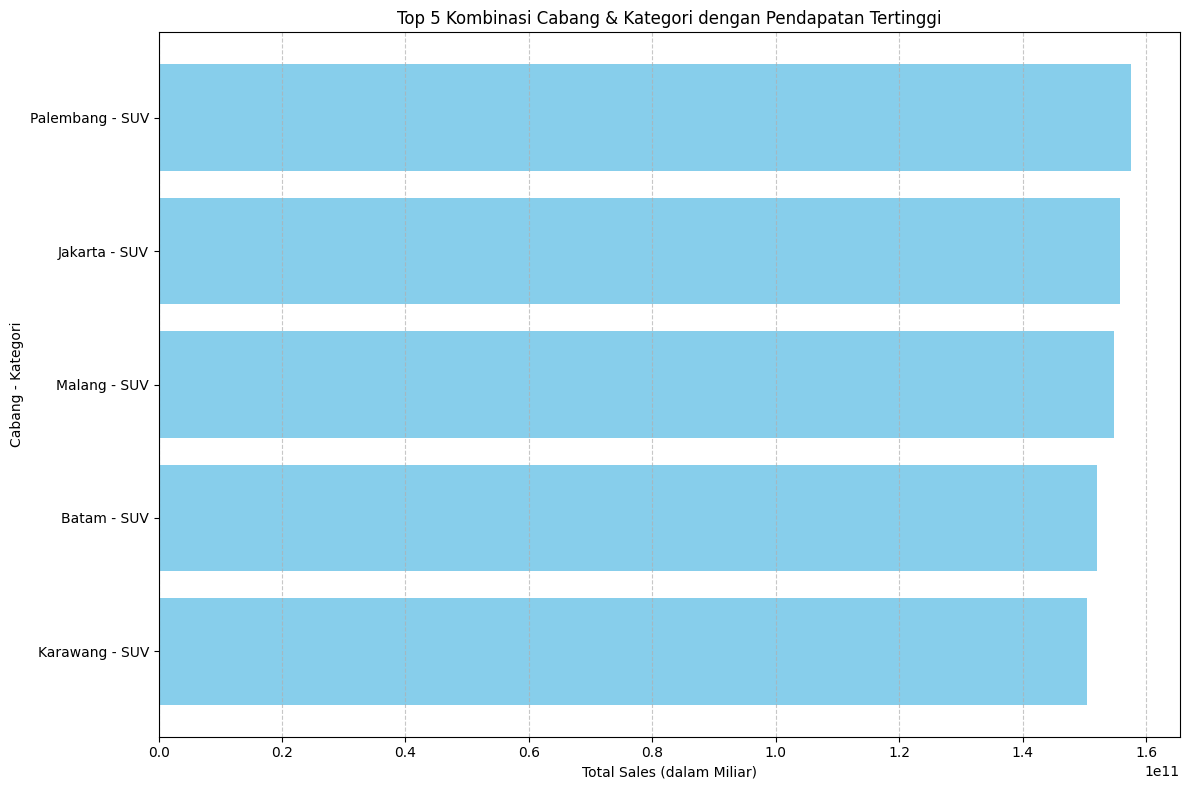

In [ ]:
# 1. Filter transaksi yang statusnya "completed"
df_completed = df[df['status'] == 'completed'].copy()

# 2. Groupby kombinasi branch dan category, jumlahkan total_sales
kombinasi_pendapatan = df_completed.groupby(['branch', 'category'])['total_sales'].sum().reset_index()

# 3. Urutkan dari terbesar, ambil 5 kombinasi teratas
kombinasi_pendapatan_teratas = kombinasi_pendapatan.sort_values(by='total_sales', ascending=False).head(5)
print("5 Kombinasi Cabang & Kategori dengan Pendapatan Tertinggi:")
display(kombinasi_pendapatan_teratas)

# 4. Buat bar chart horizontal dari 5 kombinasi teratas
plt.figure(figsize=(12, 8))
y_labels = kombinasi_pendapatan_teratas['branch'] + ' - ' + kombinasi_pendapatan_teratas['category']
plt.barh(y_labels, kombinasi_pendapatan_teratas['total_sales'], color='skyblue')
plt.xlabel('Total Sales (dalam Miliar)')
plt.ylabel('Cabang - Kategori')
plt.title('Top 5 Kombinasi Cabang & Kategori dengan Pendapatan Tertinggi')
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# (opsional) Tantangan tambahan: rata-rata harga per unit untuk 5 kombinasi teratas


---
## Selesai!

Kalau udah kelar, coba cek ulang jawaban kamu satu-satu, pastikan hasilnya masuk akal (misalnya nggak ada pendapatan yang negatif atau angka yang aneh). Selamat mengerjakan! 🚗📊
